In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/ayushuttarwar/makemore-names/names.txt


In [5]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [7]:
# read all words
words = open("/kaggle/input/datasets/ayushuttarwar/makemore-names/names.txt", 'r').read().splitlines()
print("total words: ", len(words))
print("max len word: ", max(len(w) for w in words))
print(words[:5])

total words:  32033
max len word:  15
['emma', 'olivia', 'ava', 'isabella', 'sophia']


In [8]:
# building vocabulary and mapping to ints
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0

itos = {i:s for s, i in stoi.items()}
vocab_size = len(itos)
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [9]:
# shuffle words
import random
random.seed(68)
random.shuffle(words)

In [60]:
# build dataset
block_size=8 # context length

def build_dataset(words):
    X, Y = [], []

    for w in words:
        context = [0]*block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix]

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

In [61]:
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

X_tr, Y_tr = build_dataset(words[:n1]) # 80%
X_val, Y_val = build_dataset(words[n1:n2])  # 10%
X_test, Y_test = build_dataset(words[n2:]) # 10%

torch.Size([182452, 8]) torch.Size([182452])
torch.Size([22816, 8]) torch.Size([22816])
torch.Size([22878, 8]) torch.Size([22878])


In [62]:
 for x, y in zip(X_tr[:20], Y_tr[:20]):
     print(''.join(itos[ix.item()] for ix in x), '-->', itos[y.item()])

........ --> t
.......t --> w
......tw --> i
.....twi --> s
....twis --> h
...twish --> a
..twisha --> .
........ --> t
.......t --> r
......tr --> a
.....tra --> v
....trav --> o
...travo --> n
..travon --> e
.travone --> .
........ --> a
.......a --> n
......an --> n
.....ann --> a
....anna --> l


In [64]:
# linear layer
class Linear:
    def __init__(self, fan_in, fan_out, bias=True):
        self.weight = torch.randn((fan_in, fan_out)) / fan_in**0.5 # kaiming unit
        self.bias = torch.zeros(fan_out) if bias else None

    def __call__(self, x):
        self.out = x @ self.weight
        if self.bias is not None:
            self.out += self.bias
        return self.out

    def parameters(self):
        return [self.weight] + ([] if self.bias is None else [self.bias])

In [98]:
# batch norm 1d layer
class BatchNorm1d:
    def __init__(self, dim, eps=1e-5, momentum=0.1):
        self.eps = eps
        self.momentum = momentum
        self.training=True
        # params (trained with backprop)
        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)
        # buffers (trained with a running 'momentum update')
        self.running_mean = torch.zeros(dim)
        self.running_var = torch.ones(dim)

    def __call__(self, x):
        # calculate the forward pass
        if self.training:
            if x.ndim == 2:
                dim = 0
            elif x.ndim == 3:
                dim = (1, 0)
            xmean = x.mean(dim, keepdim=True) # batch mean
            xvar = x.var(dim, keepdim=True, unbiased=True) # batch variance
        else:
            xmean = self.running_mean
            xvar = self.running_var
        xhat = (x - xmean) / torch.sqrt(xvar + self.eps) # unit normalization
        self.out = self.gamma * xhat + self.beta
        # update buffers using Exponential Moving Average (EMA)
        if self.training:
            with torch.no_grad():
                self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean
                self.running_var = (1 - self.momentum) * self.running_var + self.momentum * xvar
        return self.out

    def parameters(self):
        return (self.gamma, self.beta)

In [99]:
# tanh activation
class Tanh:
    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out
    def parameters(self):
        return []

In [100]:
# newly created modules
class Embedding:
    def __init__(self, num_embeddings, embedding_dim):
        self.weight = torch.randn((num_embeddings, embedding_dim))

    def __call__(self, IX):
        self.out = self.weight[IX]
        return self.out

    def parameters(self):
        return [self.weight]


class FlattenConsecutive:
    def __init__(self, n):
        self.n = n
        
    def __call__(self, x):
        B, T, C = x.shape
        x = x.view(B, T//self.n, C*self.n)
        if x.shape[1] == 1:
            x = x.squeeze(1)
        self.out = x
        return self.out

    def parameters(self):
        return []

In [101]:
# sequential layer container to get rid to layers[]
class Sequential:
    def __init__(self, layers):
        self.layers = layers

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        self.out = x
        return self.out

    def parameters(self):
        # get params of all layers and stretch them out into one list
        return [p for layer in self.layers for p in layer.parameters()]

In [102]:
torch.manual_seed(42) # reproducibility

In [110]:
n_embed = 24 # dimenality chars embedding vector
n_hidden = 128 # no. of neurons in hidden layer of MLP


# architecture
model = Sequential([
    Embedding(vocab_size, n_embed),
    FlattenConsecutive(2), Linear(n_embed * 2, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
    FlattenConsecutive(2), Linear(n_hidden * 2, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
    FlattenConsecutive(2), Linear(n_hidden * 2, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
    Linear(n_hidden, vocab_size),
])

with torch.no_grad():
    # last layer (make less confident)
    layers[-1].weight *= 0.1

parameters = model.parameters()
print(sum(p.nelement() for p in parameters)) # total params
for p in parameters:
    p.requires_grad = True

76579


In [104]:
# inspect
_ = model(X_tr[:4])
for layer in model.layers:
    print(layer.__class__.__name__, ":", tuple(layer.out.shape))

Embedding : (4, 8, 10)
FlattenConsecutive : (4, 4, 20)
Linear : (4, 4, 68)
BatchNorm1d : (4, 4, 68)
Tanh : (4, 4, 68)
FlattenConsecutive : (4, 2, 136)
Linear : (4, 2, 68)
BatchNorm1d : (4, 2, 68)
Tanh : (4, 2, 68)
FlattenConsecutive : (4, 136)
Linear : (4, 68)
BatchNorm1d : (4, 68)
Tanh : (4, 68)
Linear : (4, 27)


### What was happening in each layer ?

**currently input is something like this:**  

*torch.Size([4, 8])*  
example input:   
tensor([[ 0,  0,  0,  0,  0,  0,  0,  0],  
        [ 0,  0,  0,  0,  0,  0,  0,  0],  
        [ 0,  0,  0,  0, 10,  1,  3,  9],  
        [ 0,  0,  0,  0,  0,  1,  4, 22]])  

**output of embedding layer**  
shape: [4, 8, 10]

**output of flatten layer**  
shape: [4, 80]

**output of linear layer**   
shape: [4, 200]  
what's happening inside it is:  
*input * weight matrix + bias*  
eg. (torch.randn(4, 80) @ torch.randn(80, 200) + torch.randn(200))

---
In matrix multiplication,
last dim of m1 and first dim of m2 matters, other dimensions doesn't matters while performing the operation. So we don't want all 80 vectors to be fed at once. We want only 2 vectors to be fed at once and then fuse into once similarly what we have seen wavenet architecture. 

Therefore, our linear layer output must look something like this:  
(torch.randn(4, 4,20) @ torch.randn(20, 200) + torch.randn(200))

---

### What we achieved using wavenet ?
**1. To achieve our goal for new dimension of output from linear layer, we needed to redefine how flatten layer works.**  
Input shape to flatten layer is [4, 8, 10]

*what it was doing is:*  
let input to flatten layer = v

v.view(4, -1)   --> concating all the consecutive 10-d input vectors  
which then results into [4, 80] shape vector  

*changes we made to achieve our goal:*  
v.view(4, 4, 20) ***NOTE: real implementation is different it's just for understanding***
 
**2. Also we needed to fix the batchNorm layer calculation mistake which was silently performing incorrect mean calculation.**  
Earlier it was performing the batch mean and batch var over 0th dim as input as 2d but since we changed the input dim to 3d we need to calculate it over 1st dim also. So based on the dimension of input vector it must perform the calculation

In [106]:
# same optimization as it was in batchNorm
# training loop
max_steps = 200000
batch_size = 32
lossi=[]

for i in range(max_steps):
    # construct minibatch 
    ix = torch.randint(0, X_tr.shape[0], (batch_size, ))
    Xb, Yb = X_tr[ix], Y_tr[ix] # batch X, Y

    # forward pass
    logits = model(Xb)
    loss = F.cross_entropy(logits, Yb) # loss function

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update (simple SGD)
    lr = 0.1 if i < 150000 else 0.01 # step learning rate decay
    for p in parameters:
        p.data += -lr * p.grad
        
    # track stats
    if i%10000 == 0: 
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

    # break

      0/ 200000: 3.3792
  10000/ 200000: 2.5333
  20000/ 200000: 2.2931
  30000/ 200000: 1.9408
  40000/ 200000: 2.2123
  50000/ 200000: 2.0632
  60000/ 200000: 2.1374
  70000/ 200000: 2.2294
  80000/ 200000: 2.0894
  90000/ 200000: 2.5630
 100000/ 200000: 1.8706
 110000/ 200000: 1.6242
 120000/ 200000: 1.9414
 130000/ 200000: 1.7485
 140000/ 200000: 1.9595
 150000/ 200000: 1.5975
 160000/ 200000: 1.5339
 170000/ 200000: 2.1850
 180000/ 200000: 1.9488
 190000/ 200000: 1.5821


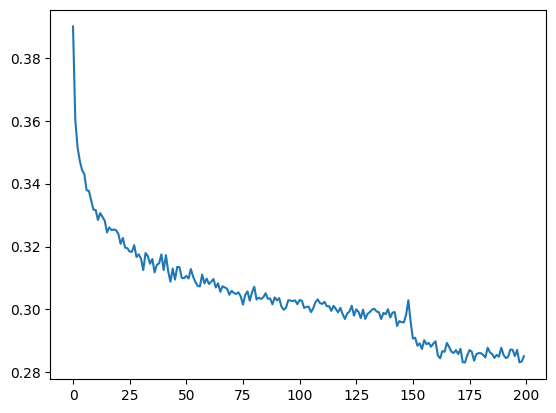

In [107]:
plt.plot(torch.tensor(lossi).view(-1, 1000).mean(1))

now here we tried to make some adjustments so that the representation will be easier to understand

sudden drop at 150 shows the learning rate decay

In [108]:
for layer in model.layers:
    layer.training= False

In [109]:
# loss evaluation
@torch.no_grad() # this decorator disables gradient tracking in pytorch
def split_loss(split):
  x,y = {
    'train': (X_tr, Y_tr),
    'val': (X_val, Y_val),
    'test': (X_test, Y_test),
  }[split]
  logits = model(x)
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

# put layers into eval mode
for layer in layers:
  layer.training = False
split_loss('train')
split_loss('val')

train 1.9073002338409424
val 2.022576093673706


## Performance Log

**original** (3 char context + 200 hidden neurons + 12K params)  
***train: 2.05; val: 2.10***

**new model** (8 char context + 22k params)  
***train: 1.91; val: 2.02***

**after redefining flatten working** (22k params)     
***train: 1.93 ; val: 2.02***

**after fixing bug in batchNorm**  
***train: 1.90; val: 2.02***
increased number of parameters in same architecture:  
***train: 1.76; val: 1.99***

In [75]:
# sample from the model
for _ in range(20):
    
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      # forward pass the neural net
      logits = model(torch.tensor([context]))
      probs = F.softmax(logits, dim=1)
      # sample from the distribution
      ix = torch.multinomial(probs, num_samples=1).item()
      # shift the context window and track the samples
      context = context[1:] + [ix]
      out.append(ix)
      # if we sample the special '.' token, break
      if ix == 0:
        break
    
    print(''.join(itos[i] for i in out)) # decode and print the generated word

melae.
lyre.
gwosen.
darryn.
zakayah.
elson.
taiony.
abelaah.
ziyah.
hamilinse.
channis.
aluxe.
ellanda.
miliana.
hamby.
denciesuh.
jaxdon.
lizan.
ronnie.
aliana.


## NOTE: I did not implement the residual connection as it was present in research paper, I just tried to replicate the architecture of how it works.